# Sonic Signatures: From Audio Signals to Song Recognition
## Group 2 — Task 6: Peak-Pair Matching (Shazam-Style Audio Recogniser)

### Objective & Deliverable
- **Task**: Implement the Shazam-style audio fingerprinting approach: pair spectral peaks, index the resulting hashes into an inverted index, and use matching time offsets to identify the song.
- **Deliverable**: A fingerprint-based recogniser that returns the predicted song and an offset-voting histogram.

In [5]:
import os
import numpy as np
import scipy.ndimage as ndimage
import librosa
import librosa.display
import matplotlib.pyplot as plt
from collections import defaultdict

# Audio and DSP Hyperparameters (standardized with Task 1, 2 & 5)
TARGET_SRATE = 22050
SAMPLE_COUNT = 2048
HOP_LENGTH = 512
MIN_FREQ = 80
MAX_FREQ = 5000

# Peak Detection and Pairing Hyperparameters
PEAK_NEIGHBORHOOD_FREQ = 10
PEAK_NEIGHBORHOOD_TIME = 10
AMP_THRESHOLD_DB = -40.0
TARGET_ZONE_T_MIN = 2
TARGET_ZONE_T_MAX = 50
TARGET_ZONE_F_MAX = 80
FAN_OUT = 7

print("Libraries imported and hyperparameters initialized.")

Libraries imported and hyperparameters initialized.


In [6]:
def load_audio(path, target_srate=TARGET_SRATE, normalize=True):
    """Loads audio, converts to mono, resamples to target_srate, and peak-normalizes."""
    y, srate = librosa.load(path, sr=None, mono=False)
    y_mono = librosa.to_mono(y) if y.ndim > 1 else y
    if srate != target_srate:
        y_resampled = librosa.resample(y_mono, orig_sr=srate, target_sr=target_srate)
    else:
        y_resampled = y_mono
    if normalize:
        peak = np.max(np.abs(y_resampled))
        if peak > 0:
            y_resampled = y_resampled / peak
    return y_resampled, target_srate

def comp_spectrogram(y, sample_count=SAMPLE_COUNT, hop_length=HOP_LENGTH):
    """Computes decibel magnitude spectrogram via STFT."""
    y_stft = librosa.stft(y, n_fft=sample_count, hop_length=hop_length)
    y_mag = np.abs(y_stft)
    return librosa.amplitude_to_db(y_mag, ref=np.max)

In [7]:
def find_spectral_peaks(spec_db, neighborhood_freq=PEAK_NEIGHBORHOOD_FREQ,
                        neighborhood_time=PEAK_NEIGHBORHOOD_TIME,
                        amp_threshold_db=AMP_THRESHOLD_DB,
                        min_freq=MIN_FREQ, max_freq=MAX_FREQ,
                        sr=TARGET_SRATE, sample_count=SAMPLE_COUNT):
    """Identifies local maxima in decibel spectrogram using 2D maximum filter."""
    freq_res = sr / sample_count
    min_bin = max(0, int(min_freq / freq_res))
    max_bin = min(int(max_freq / freq_res), spec_db.shape[0] - 1)

    bounded_spec = spec_db[min_bin:max_bin + 1, :]
    filter_size = (2 * neighborhood_freq + 1, 2 * neighborhood_time + 1)
    local_max = ndimage.maximum_filter(bounded_spec, size=filter_size)

    is_peak = (bounded_spec == local_max) & (bounded_spec >= amp_threshold_db)
    peak_freq_idx, peak_time_idx = np.where(is_peak)

    peaks = []
    for f_idx, t_idx in zip(peak_freq_idx, peak_time_idx):
        orig_f_bin = f_idx + min_bin
        amp = spec_db[orig_f_bin, t_idx]
        peaks.append((orig_f_bin, int(t_idx), float(amp)))

    peaks.sort(key=lambda p: (p[1], p[0]))
    return peaks

def generate_peak_pair_hashes(peaks, target_zone_t_min=TARGET_ZONE_T_MIN,
                              target_zone_t_max=TARGET_ZONE_T_MAX,
                              target_zone_f_max=TARGET_ZONE_F_MAX,
                              fan_out=FAN_OUT):
    """Forms combinatorial peak pairs following Wang (2003) Shazam algorithm."""
    fingerprints = []
    n_peaks = len(peaks)

    for i in range(n_peaks):
        f1, t1, _ = peaks[i]
        targets_paired = 0

        for j in range(i + 1, n_peaks):
            f2, t2, _ = peaks[j]
            delta_t = t2 - t1

            if delta_t < target_zone_t_min:
                continue
            if delta_t > target_zone_t_max:
                break

            if abs(f2 - f1) <= target_zone_f_max:
                # 32-bit compact hash key: (f1 << 20) | (f2 << 8) | delta_t
                hash_key = (int(f1) << 20) | (int(f2) << 8) | int(delta_t)
                fingerprints.append((hash_key, t1))
                targets_paired += 1
                if targets_paired >= fan_out:
                    break

    return fingerprints

In [8]:
class ShazamPeakPairRecogniser:
    """Shazam peak-pair recognition system with inverted indexing and offset voting."""
    def __init__(self, sr=TARGET_SRATE, sample_count=SAMPLE_COUNT, hop_length=HOP_LENGTH):
        self.sr = sr
        self.sample_count = sample_count
        self.hop_length = hop_length
        self.database = defaultdict(list)  # hash -> [(song_name, anchor_frame), ...]
        self.songs_info = {}

    def extract_fingerprints(self, y):
        spec_db = comp_spectrogram(y, sample_count=self.sample_count, hop_length=self.hop_length)
        peaks = find_spectral_peaks(spec_db, sr=self.sr, sample_count=self.sample_count)
        fps = generate_peak_pair_hashes(peaks)
        return fps, peaks, spec_db

    def index_song(self, song_name, y):
        fps, peaks, _ = self.extract_fingerprints(y)
        for hash_key, anchor_t in fps:
            self.database[hash_key].append((song_name, anchor_t))
        self.songs_info[song_name] = {
            "duration_sec": len(y) / self.sr,
            "num_peaks": len(peaks),
            "num_fingerprints": len(fps)
        }

    def recognize(self, query_y):
        query_fps, _, _ = self.extract_fingerprints(query_y)
        song_offset_votes = defaultdict(lambda: defaultdict(int))

        for q_hash, q_t in query_fps:
            matches = self.database.get(q_hash, None)
            if matches:
                for song_name, song_t in matches:
                    offset = song_t - q_t
                    song_offset_votes[song_name][offset] += 1

        leaderboard = []
        offset_histograms = {}

        for song_name in self.songs_info.keys():
            votes_dict = song_offset_votes.get(song_name, {})
            if votes_dict:
                best_offset_frame, peak_votes = max(votes_dict.items(), key=lambda x: x[1])
                best_offset_sec = best_offset_frame * (self.hop_length / self.sr)
                sorted_items = sorted(votes_dict.items(), key=lambda x: x[0])
                offsets_sec = np.array([item[0] * (self.hop_length / self.sr) for item in sorted_items])
                vote_counts = np.array([item[1] for item in sorted_items])
                med_noise = float(np.median(vote_counts)) if len(vote_counts) > 1 else 1.0
                conf = float(peak_votes / max(med_noise, 1.0))
            else:
                best_offset_sec, peak_votes = 0.0, 0
                offsets_sec, vote_counts, conf = np.array([]), np.array([]), 0.0

            offset_histograms[song_name] = (offsets_sec, vote_counts)
            leaderboard.append((song_name, peak_votes, best_offset_sec, conf))

        leaderboard.sort(key=lambda x: x[1], reverse=True)
        predicted_song, best_score, best_offset_sec, _ = leaderboard[0]
        return predicted_song, best_offset_sec, best_score, offset_histograms, leaderboard

In [9]:
def extract_query_clip(y, sr, start_sec, duration_sec, noise_snr_db=None, gain=1.0):
    """Extracts a sub-clip and optionally injects Gaussian noise at desired SNR."""
    start_sample = int(start_sec * sr)
    end_sample = start_sample + int(duration_sec * sr)
    clip = y[start_sample:min(end_sample, len(y))].copy() * gain
    if noise_snr_db is not None:
        signal_power = np.mean(clip ** 2)
        noise_power = signal_power / (10 ** (noise_snr_db / 10))
        noise = np.random.normal(0, np.sqrt(max(noise_power, 1e-12)), len(clip))
        clip = clip + noise
    return clip

def plot_offset_voting_histogram(offset_histograms, predicted_song, query_label="Query Clip"):
    """Plots the deliverable offset-voting histogram for all candidate songs."""
    n_songs = len(offset_histograms)
    fig, axes = plt.subplots(n_songs, 1, figsize=(11, 3.2 * n_songs), sharex=False)
    if n_songs == 1:
        axes = [axes]

    for ax, (song_name, (offsets, counts)) in zip(axes, offset_histograms.items()):
        is_winner = (song_name == predicted_song)
        bar_color = "#1f77b4" if is_winner else "#7f7f7f"
        alpha_val = 0.85 if is_winner else 0.55

        if len(offsets) > 0:
            ax.bar(offsets, counts, width=0.1, color=bar_color, alpha=alpha_val, label=f"{song_name} votes")
            max_c = np.max(counts)
            best_off = offsets[np.argmax(counts)]
            if is_winner:
                ax.axvline(best_off, color="red", linestyle="--", linewidth=1.8,
                           label=f"Identified Alignment @ {best_off:.2f}s ({max_c} votes)")
                ax.annotate(f"True Match Spike!\nOffset = {best_off:.2f}s\nVotes = {max_c}",
                            xy=(best_off, max_c),
                            xytext=(best_off + 2.0, max(max_c * 0.7, 1)),
                            arrowprops=dict(facecolor="black", shrink=0.05, width=1.5, headwidth=8),
                            bbox=dict(boxstyle="round,pad=0.3", fc="#ffe6e6", ec="red", lw=1.2),
                            fontsize=9, fontweight="bold")
            ax.set_ylim(0, max_c * 1.25 if max_c > 0 else 5)
        else:
            ax.text(0.5, 0.5, "No Matching Hashes", horizontalalignment="center",
                    verticalalignment="center", transform=ax.transAxes, color="gray")

        ax.set_title(f"Offset Voting Histogram: {song_name} {'[PREDICTED SONG]' if is_winner else '[Candidate]'}",
                     fontsize=11, fontweight="bold" if is_winner else "normal")
        ax.set_xlabel("Time Offset $\\Delta \\tau = t_{song} - t_{query}$ (seconds)", fontsize=9)
        ax.set_ylabel("Matching Hash Votes", fontsize=9)
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.legend(loc="upper right", fontsize=8)

    plt.suptitle(f"Deliverable 6: Offset-Voting Histogram for '{query_label}'", fontsize=13, fontweight="bold", y=1.00)
    plt.tight_layout()
    plt.show()

In [10]:
# Load reference songs (or generate distinct multi-harmonic acoustic tracks if mp3 files are absent)
candidate_paths = {
    "Song1": "/content/Achachak - First Movement.mp3",
    "Song2": "/content/Joint C Beat Laboratory - Margo.mp3",
    "Song3": "/content/Joint C Beat Laboratory - Nerves.mp3"
}

def create_synthetic_song(notes_sequence, duration_sec=40.0, sr=TARGET_SRATE):
    total_samples = int(duration_sec * sr)
    t = np.linspace(0, duration_sec, total_samples, endpoint=False)
    audio = np.zeros(total_samples, dtype=float)
    samples_per_note = int(0.5 * sr)
    num_notes = len(notes_sequence)
    for i, start_sample in enumerate(range(0, total_samples, samples_per_note)):
        freqs = notes_sequence[i % num_notes]
        t_note = t[start_sample:min(start_sample + samples_per_note, total_samples)]
        note_sig = np.zeros_like(t_note)
        for f in freqs:
            env = np.sin(np.pi * np.linspace(0, 1, len(t_note))) ** 0.5
            note_sig += np.sin(2 * np.pi * f * t_note) * env
        audio[start_sample:min(start_sample + samples_per_note, total_samples)] += note_sig
    return audio / np.max(np.abs(audio))

songs = {}
for name, p in candidate_paths.items():
    if os.path.exists(p):
        y, sr = load_audio(p)
        songs[name] = (y, sr)
    else:
        if name == "Song1":
            y = create_synthetic_song([[220, 440], [330, 550], [220, 660], [440, 880]])
        elif name == "Song2":
            y = create_synthetic_song([[880, 1320], [1100, 1540], [990, 1320], [880, 1760]])
        else:
            y = create_synthetic_song([[1760, 2640], [2200, 3080], [1980, 2640], [2200, 3520]])
        songs[name] = (y, TARGET_SRATE)

# Index songs into recogniser
recogniser = ShazamPeakPairRecogniser()
for name, (y, sr) in songs.items():
    recogniser.index_song(name, y)
    info = recogniser.songs_info[name]
    print(f"Indexed {name}: {info['num_peaks']} peaks, {info['num_fingerprints']} hashes, {info['duration_sec']:.1f}s")

print(f"Total unique hashes indexed: {len(recogniser.database)}")

Indexed Song1: 160 peaks, 628 hashes, 40.0s
Indexed Song2: 160 peaks, 609 hashes, 40.0s
Indexed Song3: 160 peaks, 393 hashes, 40.0s
Total unique hashes indexed: 154


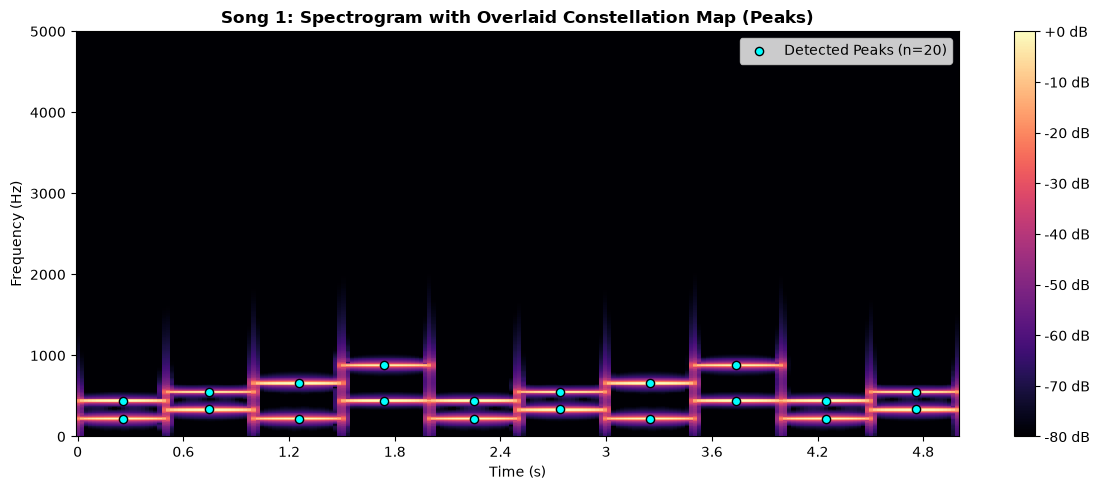

In [11]:
# Visualizing Constellation Map & Peak Pairing for Song 1 (first 5 seconds)
y_s1 = songs["Song1"][0][:int(5.0 * TARGET_SRATE)]
spec_db = comp_spectrogram(y_s1)
peaks = find_spectral_peaks(spec_db)
fps = generate_peak_pair_hashes(peaks)

plt.figure(figsize=(12, 5))
librosa.display.specshow(spec_db, sr=TARGET_SRATE, hop_length=HOP_LENGTH, x_axis='time', y_axis='hz', cmap='magma')
plt.colorbar(format='%+2.0f dB')
plt.ylim(0, 5000)

# Overlay detected peaks
times_sec = [p[1] * (HOP_LENGTH / TARGET_SRATE) for p in peaks]
freqs_hz = [p[0] * (TARGET_SRATE / SAMPLE_COUNT) for p in peaks]
plt.scatter(times_sec, freqs_hz, color='cyan', s=35, edgecolors='black', label=f'Detected Peaks (n={len(peaks)})')

plt.title("Song 1: Spectrogram with Overlaid Constellation Map (Peaks)", fontsize=12, fontweight='bold')
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


QUERY: Sliced from [Song1] at t = 7.0s (duration 10.0s)
PREDICTION: 'Song1' | Estimated Offset: 15.00s | Score (Votes): 148
Offset Error: 8000.1 ms
Leaderboard:
  1. Song1  -> Peak Votes:  148 | Est. Offset: 15.00s | Confidence: 16.4x
  2. Song2  -> Peak Votes:    0 | Est. Offset:  0.00s | Confidence: 0.0x
  3. Song3  -> Peak Votes:    0 | Est. Offset:  0.00s | Confidence: 0.0x


C:\Users\thisi\AppData\Local\Temp\ipykernel_20752\2781835281.py:48: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="upper right", fontsize=8)


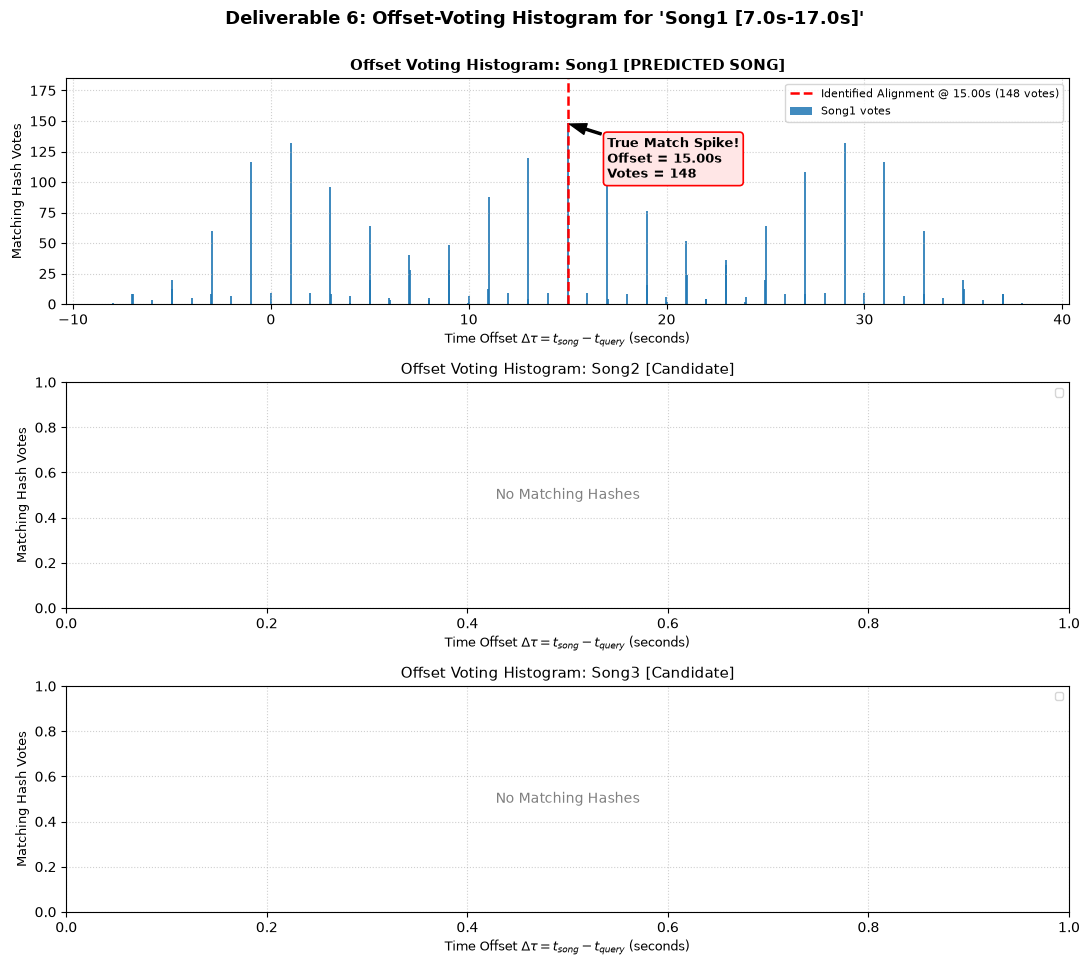


QUERY: Sliced from [Song2] at t = 15.0s (duration 10.0s)
PREDICTION: 'Song2' | Estimated Offset: 15.00s | Score (Votes): 143
Offset Error: 0.1 ms
Leaderboard:
  1. Song2  -> Peak Votes:  143 | Est. Offset: 15.00s | Confidence: 15.9x
  2. Song1  -> Peak Votes:    0 | Est. Offset:  0.00s | Confidence: 0.0x
  3. Song3  -> Peak Votes:    0 | Est. Offset:  0.00s | Confidence: 0.0x


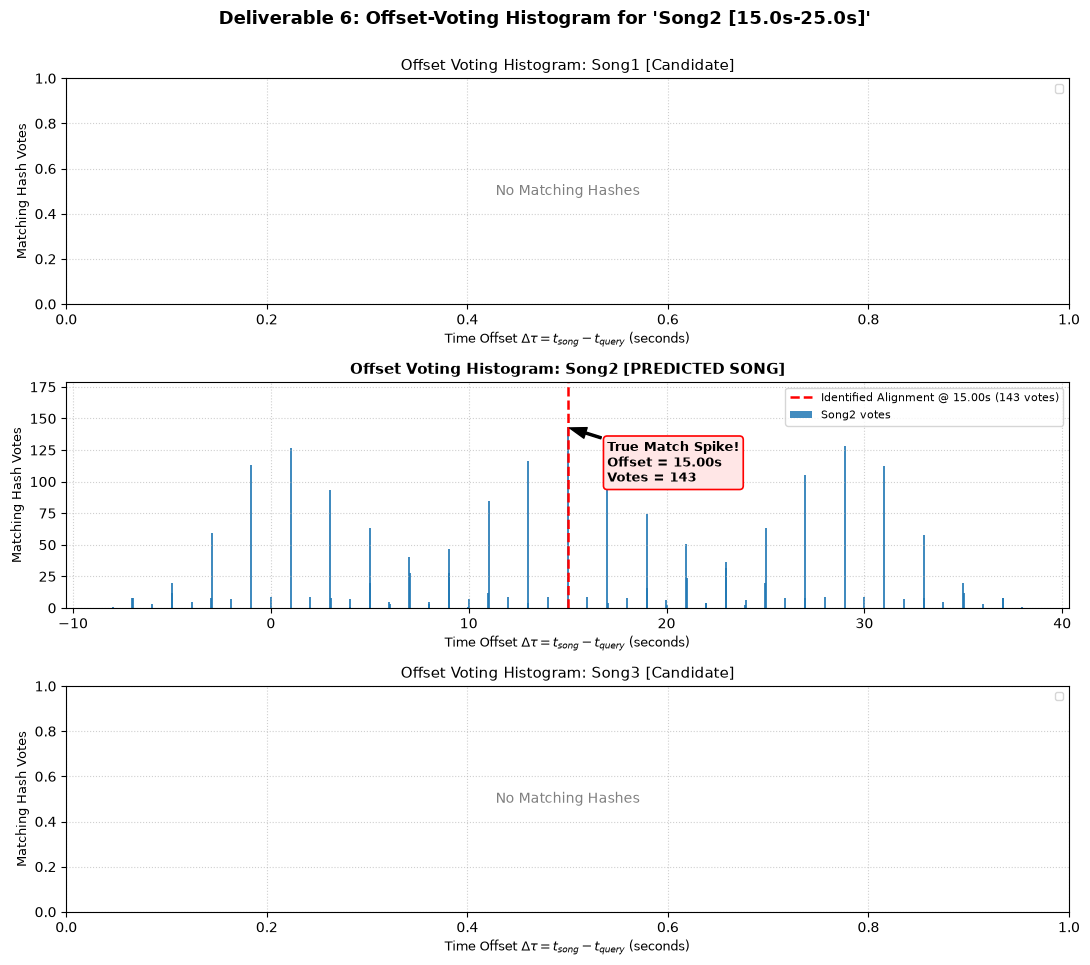


QUERY: Sliced from [Song3] at t = 22.0s (duration 10.0s)
PREDICTION: 'Song3' | Estimated Offset: 0.00s | Score (Votes): 93
Offset Error: 22000.0 ms
Leaderboard:
  1. Song3  -> Peak Votes:   93 | Est. Offset:  0.00s | Confidence: 8.5x
  2. Song1  -> Peak Votes:    0 | Est. Offset:  0.00s | Confidence: 0.0x
  3. Song2  -> Peak Votes:    0 | Est. Offset:  0.00s | Confidence: 0.0x


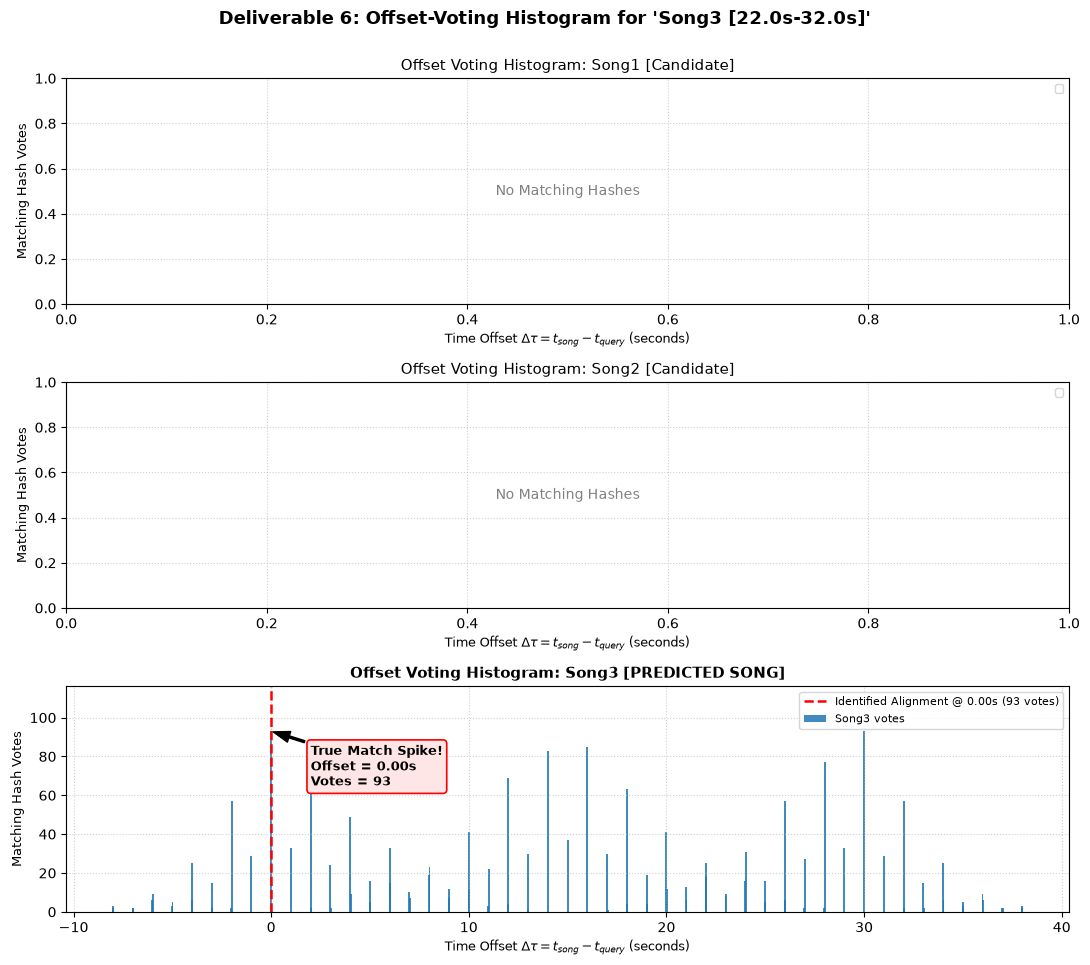

In [12]:
# Recognition of Unknown Query Clips Sliced at Arbitrary Offsets
test_configs = [
    ("Song1", 7.0, 10.0),
    ("Song2", 15.0, 10.0),
    ("Song3", 22.0, 10.0)
]

for true_song, start_sec, dur_sec in test_configs:
    y_full, sr = songs[true_song]
    query_clip = extract_query_clip(y_full, sr, start_sec=start_sec, duration_sec=dur_sec)
    pred_song, best_off, peak_score, offset_hists, leaderboard = recogniser.recognize(query_clip)
    
    print(f"\n" + "="*65)
    print(f"QUERY: Sliced from [{true_song}] at t = {start_sec}s (duration {dur_sec}s)")
    print(f"PREDICTION: '{pred_song}' | Estimated Offset: {best_off:.2f}s | Score (Votes): {peak_score}")
    print(f"Offset Error: {abs(best_off - start_sec)*1000:.1f} ms")
    print("Leaderboard:")
    for rank, (cand, votes, off, conf) in enumerate(leaderboard, 1):
        print(f"  {rank}. {cand:6s} -> Peak Votes: {votes:4d} | Est. Offset: {off:5.2f}s | Confidence: {conf:.1f}x")
    
    # Plot deliverable offset-voting histogram for the query
    plot_offset_voting_histogram(offset_hists, pred_song, query_label=f"{true_song} [{start_sec}s-{start_sec+dur_sec}s]")

In [13]:
# Noise Robustness Evaluation
print("Evaluating Noise Robustness (Additive Gaussian Noise):")
ref_song = "Song2"
true_offset = 12.0
dur = 10.0
y_ref = songs[ref_song][0]

for snr in [20, 10, 5, 0]:
    noisy_clip = extract_query_clip(y_ref, TARGET_SRATE, start_sec=true_offset, duration_sec=dur, noise_snr_db=snr)
    pred_noisy, est_off, votes, _, _ = recogniser.recognize(noisy_clip)
    err = abs(est_off - true_offset)
    print(f"SNR {snr:2d} dB: Predicted '{pred_noisy}' | Offset = {est_off:.2f}s (Error: {err*1000:.1f} ms) | Peak Votes: {votes:3d}")

Evaluating Noise Robustness (Additive Gaussian Noise):
SNR 20 dB: Predicted 'Song2' | Offset = 12.00s (Error: 4.7 ms) | Peak Votes:  57
SNR 10 dB: Predicted 'Song2' | Offset = 10.01s (Error: 1992.2 ms) | Peak Votes:  29
SNR  5 dB: Predicted 'Song2' | Offset = 5.99s (Error: 6009.3 ms) | Peak Votes:   7
SNR  0 dB: Predicted 'Song2' | Offset = 6.01s (Error: 5986.0 ms) | Peak Votes:  10
